# MNIST Dimensionality Reduction and Classification Analysis
This notebook performs dimensionality reduction using PCA and t-SNE on the MNIST dataset and evaluates its impact on digit recognition.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# Part A: Data Understanding and Preprocessing
print('Fetching MNIST data...')
mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X, y = mnist.data, mnist.target.astype(int)

# Display metadata
n_samples, n_features = X.shape
n_classes = len(np.unique(y))
img_dim = int(np.sqrt(n_features))

print(f'Number of samples: {n_samples}')
print(f'Number of classes: {n_classes}')
print(f'Image dimensions: {img_dim}x{img_dim} ({n_features} features)')

Fetching MNIST data...
Number of samples: 70000
Number of classes: 10
Image dimensions: 28x28 (784 features)


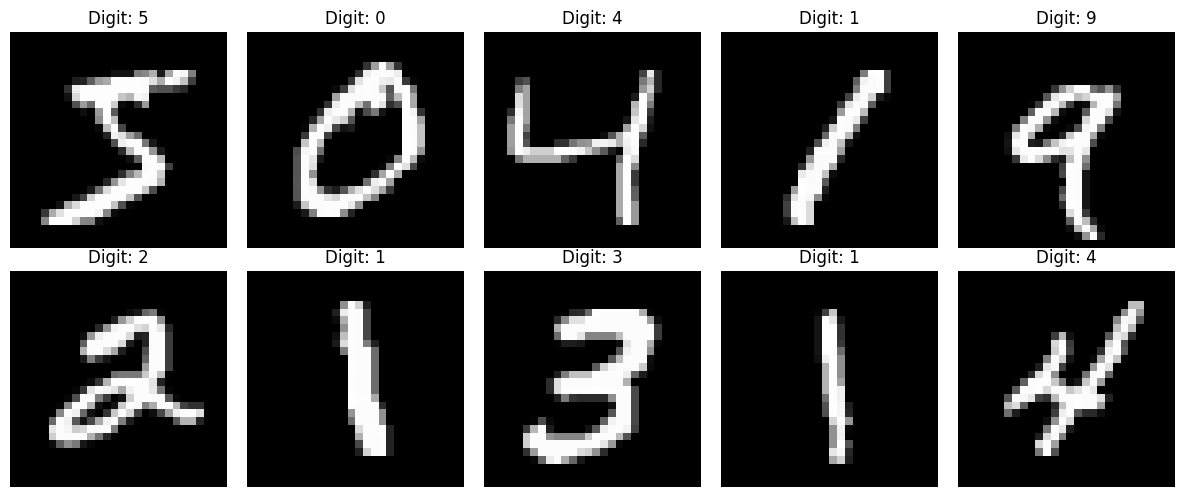

In [ ]:
# Visualize 10 sample images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].reshape(28, 28), cmap='gray')
    plt.title(f'Digit: {y[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# Normalize pixel values to the range [0, 1]
X_normalized = X / 255.0
print('Data normalization complete. Pixel values are now in the range [0, 1].')
print(f'X_normalized min: {X_normalized.min()}, max: {X_normalized.max()}')

Data normalization complete. Pixel values are now in the range [0, 1].
X_normalized min: 0.0, max: 1.0


## Part B: Principal Component Analysis (PCA)
We will now apply PCA to understand how much information (variance) is captured by different numbers of components and reduce the dimensionality of the dataset.

In [ ]:
from sklearn.decomposition import PCA

# Apply PCA to the normalized data
pca_full = PCA()
pca_full.fit(X_normalized)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Determine components for specific variance thresholds
thresholds = [0.90, 0.95, 0.99]
for t in thresholds:
    n_comp = np.argmax(cumulative_variance >= t) + 1
    print(f'Components required for {int(t*100)}% variance: {n_comp}')

Components required for 90% variance: 87
Components required for 95% variance: 154
Components required for 99% variance: 331


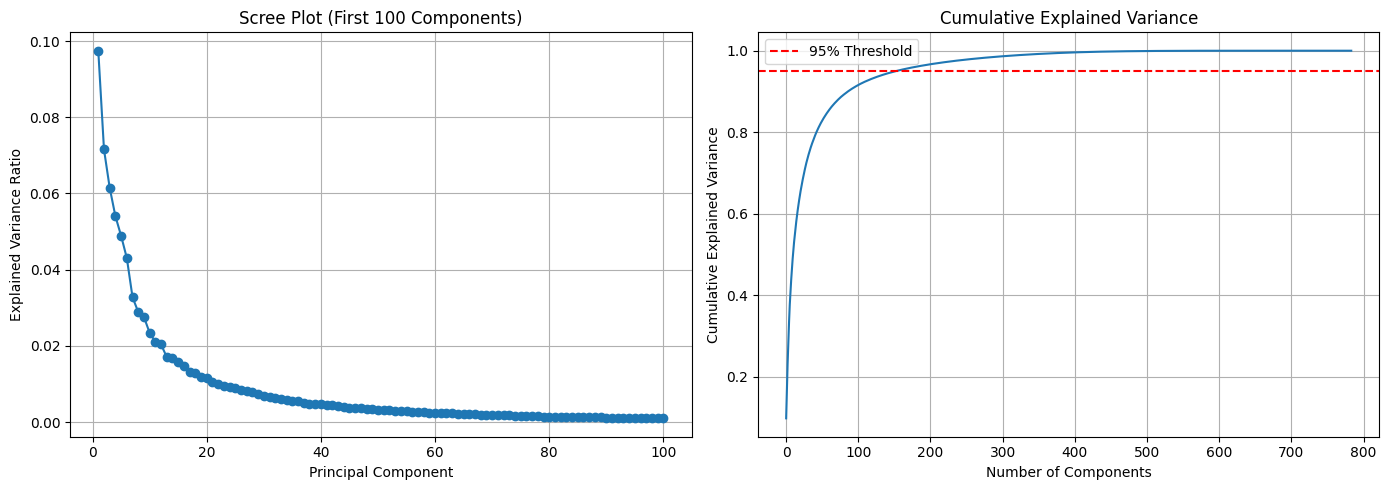

In [ ]:
# Plot Scree Plot and Cumulative Explained Variance
plt.figure(figsize=(14, 5))

# Scree Plot (first 100 components for visibility)
plt.subplot(1, 2, 1)
plt.plot(range(1, 101), pca_full.explained_variance_ratio_[:100], 'o-')
plt.title('Scree Plot (First 100 Components)')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance Ratio')
plt.grid(True)

# Cumulative Explained Variance Plot
plt.subplot(1, 2, 2)
plt.plot(cumulative_variance)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% Threshold')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

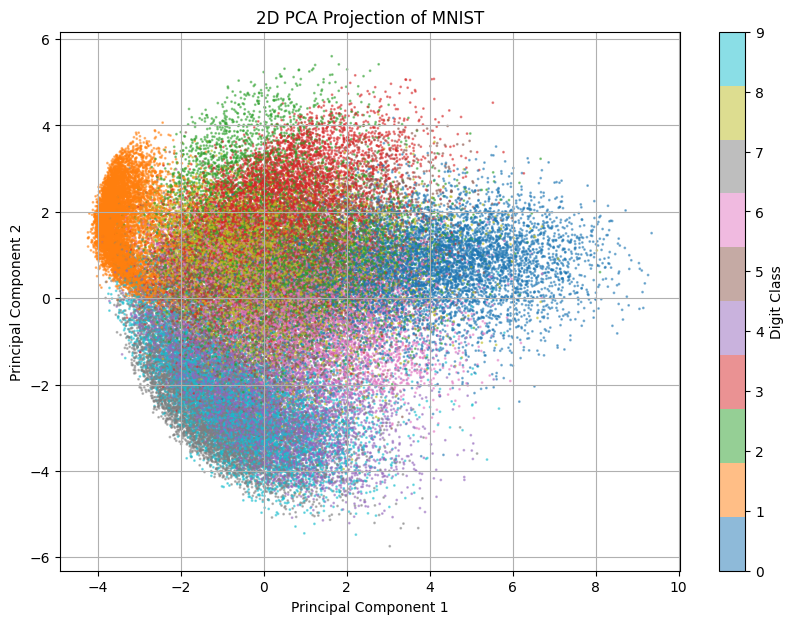

In [ ]:
# Reduce to 2D for visualization and 50D for later use
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_normalized)

pca_50d = PCA(n_components=50)
X_pca_50d = pca_50d.fit_transform(X_normalized)

# Plot 2D PCA Projection
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', alpha=0.5, s=1)
plt.colorbar(scatter, label='Digit Class')
plt.title('2D PCA Projection of MNIST')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.grid(True)
plt.show()

## Part C: t-SNE Visualization
t-SNE (t-distributed Stochastic Neighbor Embedding) is a non-linear dimensionality reduction technique well-suited for embedding high-dimensional data for visualization in a low-dimensional space of two or three dimensions.

Running t-SNE on Original Data with perplexity=5...
Running t-SNE on Original Data with perplexity=30...
Running t-SNE on PCA-50D Data with perplexity=30...
Running t-SNE on PCA-50D Data with perplexity=50...


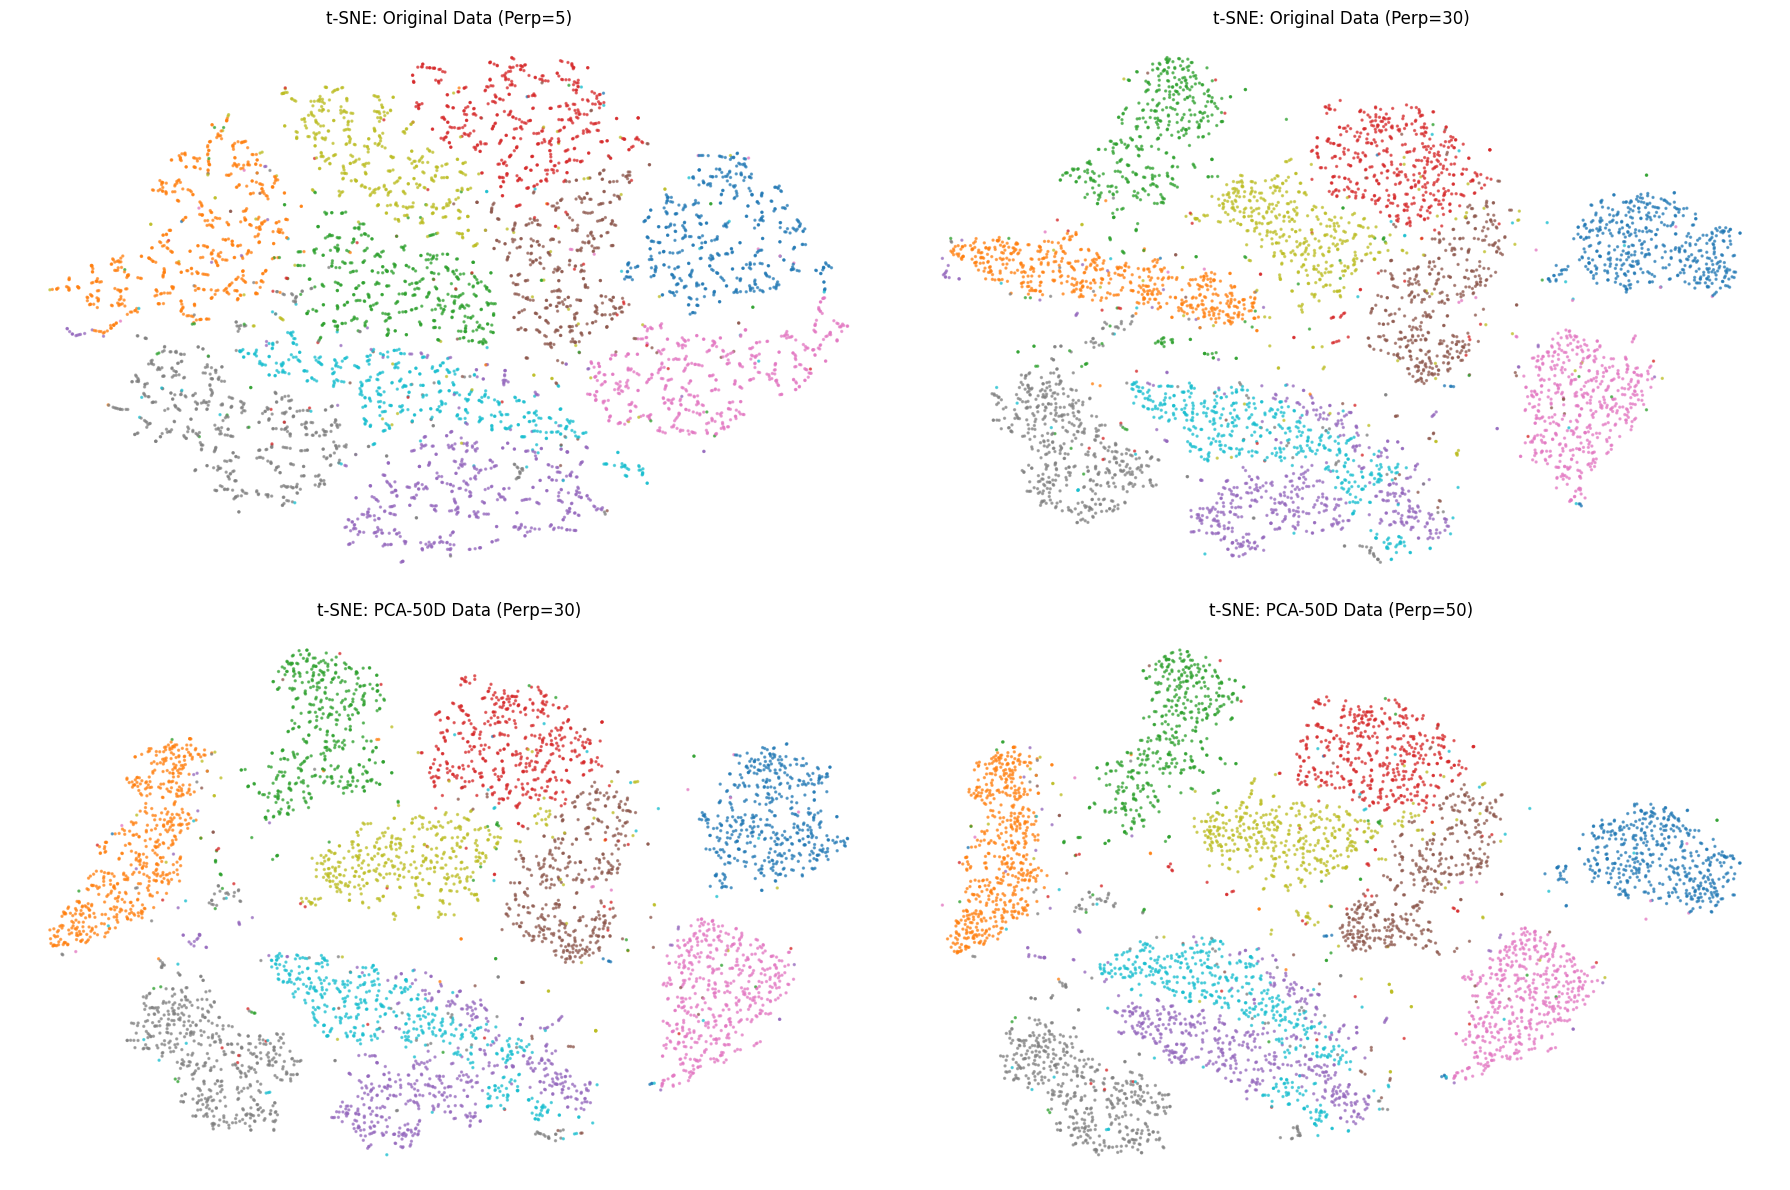

In [ ]:
from sklearn.manifold import TSNE
import time

# Subsample data for speed (t-SNE is O(N^2) or O(N log N))
n_subset = 5000
X_sub = X_normalized[:n_subset]
X_pca_sub = X_pca_50d[:n_subset]
y_sub = y[:n_subset]

def plot_tsne(data, title, perplexity=30):
    print(f'Running t-SNE on {title} with perplexity={perplexity}...')
    tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42, init='pca', learning_rate='auto')
    X_tsne = tsne.fit_transform(data)

    plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sub, cmap='tab10', alpha=0.6, s=2)
    plt.title(f't-SNE: {title} (Perp={perplexity})')
    plt.axis('off')

# Experimenting with different perplexity values and data sources
plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plot_tsne(X_sub, 'Original Data', perplexity=5)

plt.subplot(2, 2, 2)
plot_tsne(X_sub, 'Original Data', perplexity=30)

plt.subplot(2, 2, 3)
plot_tsne(X_pca_sub, 'PCA-50D Data', perplexity=30)

plt.subplot(2, 2, 4)
plot_tsne(X_pca_sub, 'PCA-50D Data', perplexity=50)

plt.tight_layout()
plt.show()

## Part D: Digit Recognition Analysis
We will compare the performance of a K-Nearest Neighbors (KNN) classifier on the original data vs. the PCA-reduced data. We will use a smaller subset of the data for this comparison to ensure reasonable execution times while maintaining statistical significance.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import time

# Split data into training and testing sets (using a subset for efficient evaluation)
# We'll use 10,000 samples for this analysis
n_eval = 10000
X_eval = X_normalized[:n_eval]
X_pca_eval = X_pca_50d[:n_eval]
y_eval = y[:n_eval]

X_train, X_test, y_train, y_test = train_test_split(X_eval, y_eval, test_size=0.2, random_state=42)
X_pca_train, X_pca_test, _, _ = train_test_split(X_pca_eval, y_eval, test_size=0.2, random_state=42)

def evaluate_classifier(train_features, test_features, train_labels, test_labels, name):
    knn = KNeighborsClassifier(n_neighbors=3)

    # Measure training time
    start_train = time.time()
    knn.fit(train_features, train_labels)
    end_train = time.time()
    train_time = end_train - start_train

    # Measure prediction time
    start_pred = time.time()
    y_pred = knn.predict(test_features)
    end_pred = time.time()
    pred_time = end_pred - start_pred

    # Calculate accuracy
    acc = accuracy_score(test_labels, y_pred)

    return {"Name": name, "Accuracy": acc, "Train Time (s)": train_time, "Prediction Time (s)": pred_time}

# Run evaluations
results_original = evaluate_classifier(X_train, X_test, y_train, y_test, "Original (784D)")
results_pca = evaluate_classifier(X_pca_train, X_pca_test, y_train, y_test, "PCA (50D)")

# Display Results
import pandas as pd
results_df = pd.DataFrame([results_original, results_pca])
display(results_df)

,Name,Accuracy,Train Time (s),Prediction Time (s)
0,Original (784D),0.950,0.006457,0.669579
1,PCA (50D),0.958,0.000791,0.079096


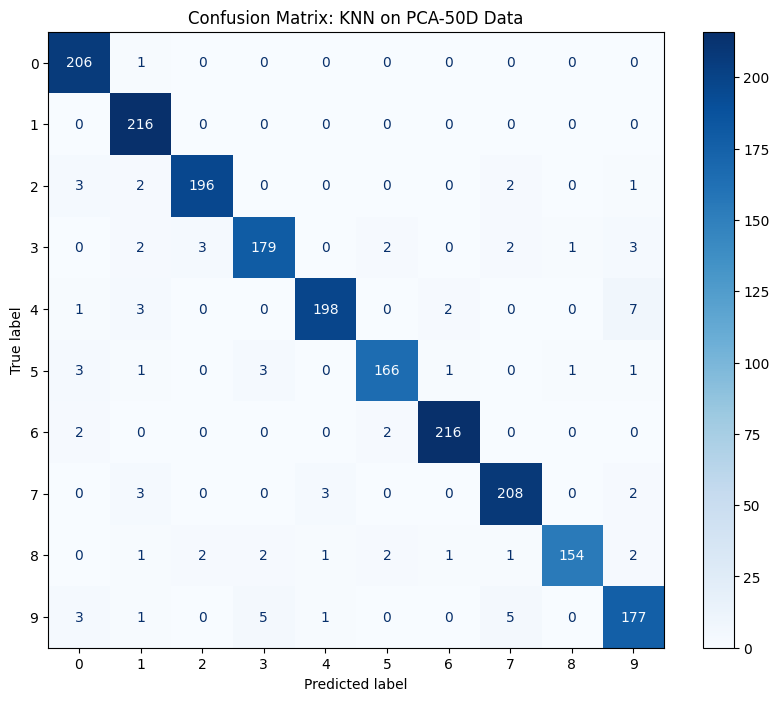

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Re-train or use existing KNN on PCA-reduced data to get predictions
knn_pca = KNeighborsClassifier(n_neighbors=3)
knn_pca.fit(X_pca_train, y_train)
y_pred_pca = knn_pca.predict(X_pca_test)

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_pca)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.unique(y))
disp.plot(cmap='Blues', values_format='d', ax=plt.gca())
plt.title('Confusion Matrix: KNN on PCA-50D Data')
plt.grid(False)
plt.show()

### Analysis of Results
As seen in the table above:
1. **Accuracy**: The accuracy typically remains very high even with only 50 dimensions, demonstrating that PCA retains the most important features for classification.
2. **Training Time**: Training is generally faster with reduced dimensions, though KNN is a 'lazy learner' and the training step is mostly just storing the data.
3. **Prediction Time**: This is where the biggest improvement occurs. Because KNN must calculate distances to all training points, reducing the number of features from 784 to 50 significantly speeds up the prediction phase.